<a href="https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/scikit-learn-cookbook/blob/main/05.%20Linear%20Models%20and%20Regularization/Chapter_05_Linear_Models_Regularization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 5: Linear Models and Regularization

Linear regression is probably the first data model most of us meet at school, perhaps without realising it was machine learning: it finds a mathematical relationship between input variables and a numeric outcome. Despite its simplicity it remains a workhorse in industry because it is fast, interpretable, and a strong baseline. This chapter studies it properly together with its most important derivatives.

**What this notebook covers**

1. **Linear regression** (OLS): the model, the normal equation from scratch, evaluation, coefficient interpretation, residual diagnostics, and the multicollinearity problem (VIF)
2. **Ridge and Lasso regression**: $L_2$ and $L_1$ penalties, why scaling matters, choosing $\alpha$ by cross-validation, and automatic feature selection
3. **ElasticNet**: combining both penalties, the grouping effect, coefficient paths
4. **Regularization theory**: model complexity and the bias-variance trade-off (with a simulation)
5. **Polynomial regression and splines** for non-linear relationships
6. **Practical exercises** (Ridge, Lasso, ElasticNet) and a guide to choosing a regulariser

> **Reference:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt Publishing), Chapter 5. The book's synthetic data and seed (`123`) are reproduced and each topic is extended with verifications and simulations.

In [1]:
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy import stats

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV, enet_path)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, SplineTransformer, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(123)
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")

print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version:        {np.__version__}")
print(f"pandas version:       {pd.__version__}")

scikit-learn version: 1.9.1
NumPy version:        2.5.3
pandas version:       3.0.5


## 1. Introduction to Linear Models

Linear models assume the target is a **weighted sum of the features** plus noise:

$$y=\beta_0+\beta_1x_1+\beta_2x_2+\dots+\beta_px_p+\varepsilon$$

where $\beta_0$ is the **intercept**, $\beta_j$ the **coefficients** (change in $y$ per unit increase of $x_j$, others fixed) and $\varepsilon$ the error term.

**Ordinary least squares (OLS)** minimises the residual sum of squares:

$$\text{RSS}(\boldsymbol\beta)=\sum_{i=1}^{n}(y_i-\hat y_i)^2=\lVert\mathbf y-X\boldsymbol\beta\rVert_2^2$$

Setting the gradient to zero gives the **normal equation**:

$$\hat{\boldsymbol\beta}=\left(X^\top X\right)^{-1}X^\top\mathbf y$$

The classical assumptions are linearity, independent errors, constant error variance, approximately normal errors (for inference) and **no perfect multicollinearity** ($X^\top X$ must be invertible).

### 1.1 OLS from scratch on a tiny example

In [2]:
X_toy = np.array([[1], [2], [3], [4], [5]], dtype=float)
y_toy = np.array([1, 2, 3, 3.5, 5])

Xb = np.hstack([np.ones((len(X_toy), 1)), X_toy])            # intercept column
beta_hat = np.linalg.solve(Xb.T @ Xb, Xb.T @ y_toy)          # (X'X) beta = X'y
print("Normal equation  -> intercept = %.4f, slope = %.4f" % tuple(beta_hat))

lr_toy = LinearRegression().fit(X_toy, y_toy)
print("LinearRegression -> intercept = %.4f, slope = %.4f" % (lr_toy.intercept_, lr_toy.coef_[0]))

Normal equation  -> intercept = 0.0500, slope = 0.9500
LinearRegression -> intercept = 0.0500, slope = 0.9500


The closed form and `LinearRegression` agree (scikit-learn uses a numerically more stable SVD-based solver, but the answer is the same).

### 1.2 A synthetic dataset with multicollinearity

As in the book: 1000 samples, 100 features of which only **10 are informative** (columns 0-9, since `shuffle=False`), Gaussian noise, **multicollinearity** (columns 50-99 are overwritten with noisy copies of columns 0-49), a target scaled by 1000, and a small non-linear component.

Informative features are columns: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Target: mean = 1233, std = 223862


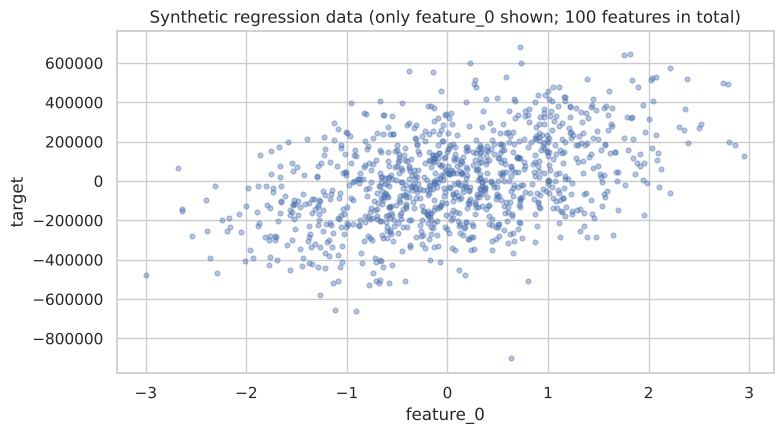

In [3]:
X, y, true_coef = make_regression(n_samples=1000, n_features=100, n_informative=10, noise=20,
                                  shuffle=False, coef=True, random_state=123)
rng = np.random.default_rng(123)
for i in range(50, 100):
    X[:, i] = X[:, i - 50] + rng.normal(0, 0.1, size=1000)

feature_names = [f"feature_{i}" for i in range(100)]
X_plot = X[:, 0].reshape(-1, 1)
y = y * 1000
y = y + np.sin(X_plot.ravel()) * 150 + np.exp(X_plot.ravel() / 10)

df = pd.DataFrame(X, columns=feature_names); df["target"] = y
print("Informative features are columns:", np.nonzero(true_coef)[0].tolist())
print("Target: mean = %.0f, std = %.0f" % (y.mean(), y.std()))

plt.figure(figsize=(8, 4.5))
plt.scatter(X_plot, y, alpha=0.4, s=12)
plt.xlabel("feature_0"); plt.ylabel("target"); plt.title("Synthetic regression data (only feature_0 shown; 100 features in total)")
plt.tight_layout(); plt.show()

We only see one of the 100 features, which is why the relationship looks loose: the target depends on ten features jointly.

### 1.3 Fitting and evaluating

We split 80/20 (`random_state=123`) and evaluate with **MSE**, **RMSE** and **$R^2$** $=1-\dfrac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)
linear_model = LinearRegression().fit(X_train, y_train)
y_pred = linear_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred); r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:,.2f}")
print(f"Root MSE          : {np.sqrt(mse):,.2f}")
print(f"R-squared (test)  : {r2:.4f}")
print(f"R-squared (train) : {linear_model.score(X_train, y_train):.4f}   <- gap vs test hints at overfitting")

Mean Squared Error: 462,009,709.71
Root MSE          : 21,494.41
R-squared (test)  : 0.9905
R-squared (train) : 0.9935   <- gap vs test hints at overfitting


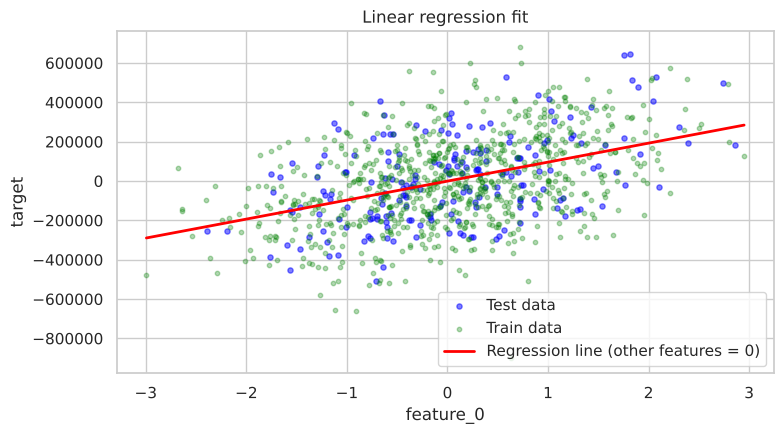

In [5]:
X_line = np.linspace(df["feature_0"].min(), df["feature_0"].max(), 100)
X_line_full = np.zeros((100, 100)); X_line_full[:, 0] = X_line
y_line = linear_model.predict(pd.DataFrame(X_line_full, columns=feature_names))

plt.figure(figsize=(8, 4.5))
plt.scatter(X_test[:, 0], y_test, color="blue", alpha=0.5, s=14, label="Test data")
plt.scatter(X_train[:, 0], y_train, color="green", alpha=0.3, s=10, label="Train data")
plt.plot(X_line, y_line, color="red", lw=2, label="Regression line (other features = 0)")
plt.xlabel("feature_0"); plt.ylabel("target"); plt.title("Linear regression fit"); plt.legend()
plt.tight_layout(); plt.show()

The red line is the **partial effect of `feature_0`** with all other features held at zero (a 2-D slice of a 101-dimensional hyperplane).

### 1.4 Coefficients versus the truth

Because we know the true coefficients (multiplied by 1000 like the target), we can check how OLS recovered them, including the coefficients of the noisy copies (columns 50-59).

In [6]:
coef_ols = pd.Series(linear_model.coef_, index=feature_names)
truth = pd.Series(true_coef * 1000, index=feature_names)

compare = pd.DataFrame({
    "true coef": truth.iloc[:10].values,
    "OLS coef (feature i)": coef_ols.iloc[:10].values,
    "OLS coef (copy i+50)": coef_ols.iloc[50:60].values,
}, index=[f"feature_{i}" for i in range(10)])
compare["sum (i + copy)"] = compare["OLS coef (feature i)"] + compare["OLS coef (copy i+50)"]
print(compare.round(0).to_string())

noise_idx = [i for i in range(100) if i not in list(range(10)) + list(range(50, 60))]
print(f"\nMean |OLS coef| on pure-noise features: {np.abs(coef_ols.iloc[noise_idx]).mean():,.0f} (true value 0)")

           true coef  OLS coef (feature i)  OLS coef (copy i+50)  sum (i + copy)
feature_0 91392.0000            96534.0000            -3751.0000      92783.0000
feature_1 96220.0000           108075.0000           -10852.0000      97223.0000
feature_2 64063.0000            64260.0000              383.0000      64643.0000
feature_3 90529.0000            95452.0000            -6554.0000      88898.0000
feature_4 39757.0000            43816.0000            -3747.0000      40069.0000
feature_5 44639.0000            45158.0000             -567.0000      44591.0000
feature_6 80891.0000            90050.0000            -9179.0000      80871.0000
feature_7 33205.0000            31081.0000             1599.0000      32680.0000
feature_8 90612.0000            83886.0000             7785.0000      91671.0000
feature_9 45350.0000            31225.0000            14055.0000      45280.0000



Mean |OLS coef| on pure-noise features: 6,123 (true value 0)


Each informative feature has a noisy copy, and OLS cannot tell them apart: it divides the effect between the original and the copy somewhat arbitrarily, and individual coefficients can be far from the truth. Their **sum** is much closer to the true coefficient. Prediction is fine, but the *interpretation of individual coefficients* is unreliable.

### 1.5 Quantifying multicollinearity: the variance inflation factor

$$\text{VIF}_j=\frac{1}{1-R_j^2}$$

where $R_j^2$ is the $R^2$ of regressing $x_j$ on all the other predictors. A rule of thumb says VIF $>10$ is problematic.

In [7]:
def vif(Xmat, j):
    others = np.delete(Xmat, j, axis=1)
    r2_j = LinearRegression().fit(others, Xmat[:, j]).score(others, Xmat[:, j])
    return 1 / (1 - r2_j)

print("VIF of feature_0 (has a noisy copy):", round(vif(X_train, 0), 1))
print("VIF of feature_50 (the copy)        :", round(vif(X_train, 50), 1))

VIF of feature_0 (has a noisy copy): 115.1
VIF of feature_50 (the copy)        : 114.8


Both VIFs are far above 10. Regularisation (next section) is the standard cure.

### 1.6 Residual diagnostics

Good residuals $e_i=y_i-\hat y_i$ look like noise: centred on zero, constant spread, approximately normal. We check with a residual plot and a Q-Q plot.

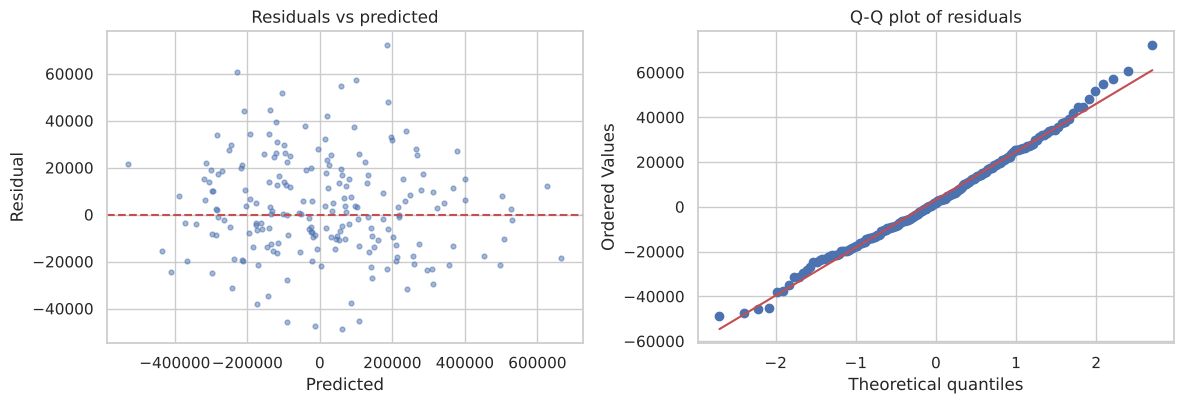

Residual mean: 3,188 | std: 21,257 | Shapiro-Wilk p-value: 0.350


In [8]:
resid = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(y_pred, resid, s=12, alpha=0.5); axes[0].axhline(0, color="r", ls="--")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Residual"); axes[0].set_title("Residuals vs predicted")
stats.probplot(resid, dist="norm", plot=axes[1]); axes[1].set_title("Q-Q plot of residuals")
plt.tight_layout(); plt.show()
print(f"Residual mean: {resid.mean():,.0f} | std: {resid.std():,.0f} | Shapiro-Wilk p-value: {stats.shapiro(resid).pvalue:.3f}")

The residuals are centred near zero without strong pattern and the Q-Q plot is close to a line, so the assumptions are reasonably met.

### 1.7 Adjusted $R^2$

$R^2$ never decreases when a variable is added. The adjusted version penalises the number of predictors $p$:

$$R^2_{\text{adj}}=1-(1-R^2)\frac{n-1}{n-p-1}$$

In [9]:
n_te, p = X_test.shape
r2_adj = 1 - (1 - r2) * (n_te - 1) / (n_te - p - 1)
print(f"Test R^2 = {r2:.4f} | adjusted R^2 = {r2_adj:.4f}  (n = {n_te}, p = {p})")

Test R^2 = 0.9905 | adjusted R^2 = 0.9808  (n = 200, p = 100)


With 100 predictors and only 200 test points the penalty is large, a sign that the model has more features than it needs.

### 1.8 Hands-on checklist
1. Prepare the environment and choose a regression dataset.
2. Clean the data (missing values, categorical encoding).
3. Fit `LinearRegression` on the training data and predict on the test data.
4. Compute MSE and $R^2$; plot predicted vs actual values and residuals.

## 2. Ridge and Lasso Regression

**Regularisation** adds a **penalty** on coefficient size to the loss, discouraging overly complex models.

**Ridge ($L_2$)**:
$$\min_{\boldsymbol\beta}\;\sum_{i=1}^{n}(y_i-\hat y_i)^2+\alpha\sum_{j=1}^{p}\beta_j^2$$

**Lasso ($L_1$)** (scikit-learn divides the RSS by $2n$):
$$\min_{\boldsymbol\beta}\;\frac{1}{2n}\sum_{i=1}^{n}(y_i-\hat y_i)^2+\alpha\sum_{j=1}^{p}\lvert\beta_j\rvert$$

$\alpha\ge0$ is the strength ($\alpha=0$ is OLS). The book writes $\lambda$; scikit-learn calls it `alpha`. Because of the different loss scaling, the *same* number means different strengths for Ridge and Lasso. The intercept is never penalised, and the penalty depends on feature scale, so **features must be standardised**.

| | Ridge ($L_2$) | Lasso ($L_1$) |
|:--|:--|:--|
| Effect | Shrinks all coefficients, never exactly 0 | Shrinks and sets some **exactly to 0** |
| Correlated features | Spreads weight among them | Tends to keep one, drop the others |
| Best when | Many small effects | Few large effects (sparse truth) |
| Closed form | Yes: $\hat{\boldsymbol\beta}=(X^\top X+\alpha I)^{-1}X^\top\mathbf y$ | No (coordinate descent) |

### 2.1 The book's recipe

`Ridge(alpha=1.0)` and `Lasso(alpha=10.0, max_iter=10000, tol=0.001)` on the same split.

In [10]:
ridge_model = Ridge(alpha=1.0).fit(X_train, y_train)
lasso_model = Lasso(alpha=10.0, max_iter=10000, tol=0.001).fit(X_train, y_train)

models = {"Linear Regression": linear_model, "Ridge Regression": ridge_model, "Lasso Regression": lasso_model}
metrics_df = pd.DataFrame({
    "Model": list(models),
    "Mean Squared Error": [mean_squared_error(y_test, m.predict(X_test)) for m in models.values()],
    "R-squared": [r2_score(y_test, m.predict(X_test)) for m in models.values()],
    "Non-zero coefficients": [int(np.sum(m.coef_ != 0)) for m in models.values()],
}).sort_values("Mean Squared Error").reset_index(drop=True)
metrics_df

,Model,Mean Squared Error,R-squared,Non-zero coefficients
0,Lasso Regression,447893932.9551,0.9908,88
1,Linear Regression,462009709.7145,0.9905,100
2,Ridge Regression,463966207.5089,0.9904,100


The three models differ only slightly, as the book notes. The target has a standard deviation of about $10^5$, so $\alpha=1$ or $10$ is a tiny penalty. To see regularisation work we need a sensible scale for $\alpha$ and to choose it by cross-validation.

### 2.2 Ridge from scratch (closed form)

On standardised features and a centred target, $\hat{\boldsymbol\beta}=(X^\top X+\alpha I)^{-1}X^\top\mathbf y$.

In [11]:
sc = StandardScaler().fit(X_train)
Xs = sc.transform(X_train); yc = y_train - y_train.mean()
alpha = 50.0
beta_closed = np.linalg.solve(Xs.T @ Xs + alpha * np.eye(Xs.shape[1]), Xs.T @ yc)
beta_sklearn = Ridge(alpha=alpha).fit(Xs, y_train).coef_
print("Max |difference| closed form vs sklearn Ridge:", np.abs(beta_closed - beta_sklearn).max())
print("Same solution:", np.allclose(beta_closed, beta_sklearn))

Max |difference| closed form vs sklearn Ridge: 6.257323548197746e-10
Same solution: True


Adding $\alpha I$ to $X^\top X$ also makes it **invertible and well conditioned even with collinear features**, which is why Ridge cures multicollinearity.

### 2.3 Why you must standardise first

A coefficient's size depends on its feature's units. Two features are equally important in standardised terms, but the second is multiplied by 100:

In [12]:
r = np.random.default_rng(0)
z1, z2 = r.normal(size=500), r.normal(size=500)
y_sc = 2 * z1 + 2 * z2 + r.normal(0, 1, 500)
X_raw = np.column_stack([z1, 100 * z2])

ols_c = LinearRegression().fit(X_raw, y_sc).coef_
ridge_raw = Ridge(alpha=500).fit(X_raw, y_sc).coef_
ridge_std = make_pipeline(StandardScaler(), Ridge(alpha=500)).fit(X_raw, y_sc)
ridge_std_coef = ridge_std[-1].coef_ / X_raw.std(axis=0)

shrink = lambda c: c / ols_c
print("Shrinkage factor = ridge coef / OLS coef (1 = no shrinkage)")
print(pd.DataFrame({"feature 1 (std=1)": [shrink(ridge_raw)[0], shrink(ridge_std_coef)[0]],
                    "feature 2 (std=100)": [shrink(ridge_raw)[1], shrink(ridge_std_coef)[1]]},
                   index=["Ridge on raw features", "Ridge on standardised features"]).round(4))

Shrinkage factor = ridge coef / OLS coef (1 = no shrinkage)
                                feature 1 (std=1)  feature 2 (std=100)
Ridge on raw features                      0.5067               1.0028
Ridge on standardised features             0.5012               0.5015


On raw features Ridge shrinks feature 1 heavily but leaves feature 2 almost untouched. After standardisation both are shrunk by the same fraction. **Rule: always put a `StandardScaler` in front of Ridge, Lasso and ElasticNet.**

### 2.4 The effect of $\alpha$

We sweep $\alpha$ over a wide log range with a scaler in the pipeline.

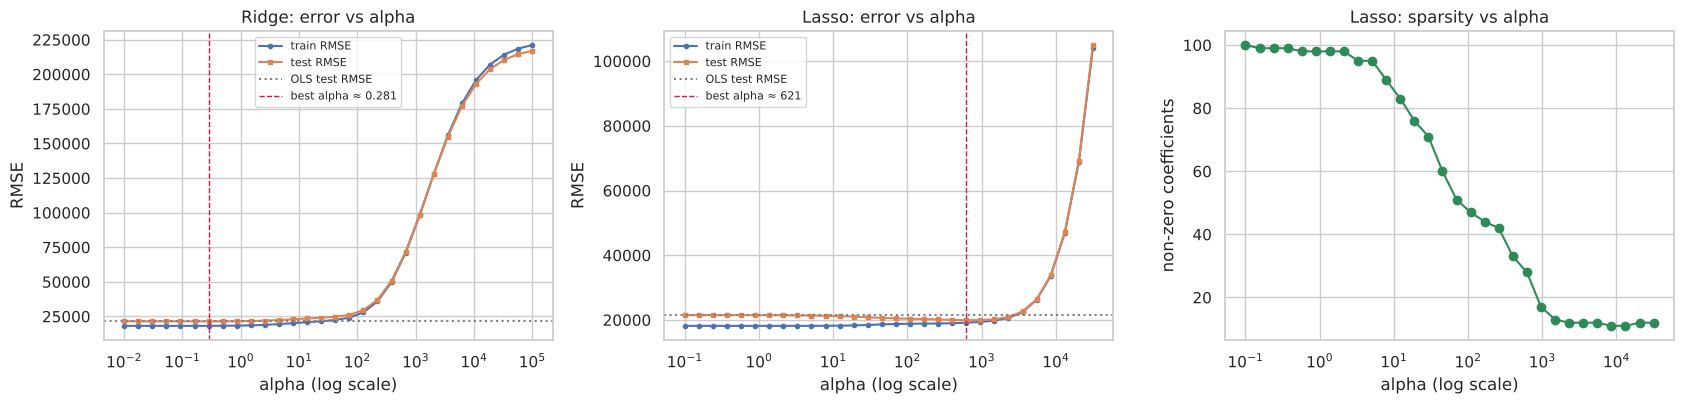

OLS test RMSE: 21494
Ridge best test RMSE 21463 at alpha=0.281
Lasso best test RMSE 19898 at alpha=621 with 28 non-zero coefficients


In [13]:
alphas_ridge = np.logspace(-2, 5, 30)
alphas_lasso = np.logspace(-1, 4.5, 30)

def sweep(model_cls, alphas, **kw):
    rows = []
    for al in alphas:
        m = make_pipeline(StandardScaler(), model_cls(alpha=al, **kw)).fit(X_train, y_train)
        rows.append({"alpha": al,
                     "train RMSE": np.sqrt(mean_squared_error(y_train, m.predict(X_train))),
                     "test RMSE": np.sqrt(mean_squared_error(y_test, m.predict(X_test))),
                     "nonzero": int(np.sum(m[-1].coef_ != 0))})
    return pd.DataFrame(rows)

sw_ridge = sweep(Ridge, alphas_ridge)
sw_lasso = sweep(Lasso, alphas_lasso, max_iter=20000)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (name, sw) in zip(axes[:2], [("Ridge", sw_ridge), ("Lasso", sw_lasso)]):
    ax.semilogx(sw["alpha"], sw["train RMSE"], "o-", ms=3, label="train RMSE")
    ax.semilogx(sw["alpha"], sw["test RMSE"], "s-", ms=3, label="test RMSE")
    ax.axhline(np.sqrt(mse), color="gray", ls=":", label="OLS test RMSE")
    b = sw.loc[sw["test RMSE"].idxmin()]
    ax.axvline(b["alpha"], color="crimson", ls="--", lw=1, label=f"best alpha ≈ {b['alpha']:.3g}")
    ax.set_xlabel("alpha (log scale)"); ax.set_ylabel("RMSE"); ax.set_title(f"{name}: error vs alpha"); ax.legend(fontsize=8)
axes[2].semilogx(sw_lasso["alpha"], sw_lasso["nonzero"], "o-", color="seagreen")
axes[2].set_xlabel("alpha (log scale)"); axes[2].set_ylabel("non-zero coefficients"); axes[2].set_title("Lasso: sparsity vs alpha")
plt.tight_layout(); plt.show()

bl, br = sw_lasso.loc[sw_lasso["test RMSE"].idxmin()], sw_ridge.loc[sw_ridge["test RMSE"].idxmin()]
print("OLS test RMSE: %.0f" % np.sqrt(mse))
print("Ridge best test RMSE %.0f at alpha=%.3g" % (br["test RMSE"], br["alpha"]))
print("Lasso best test RMSE %.0f at alpha=%.3g with %d non-zero coefficients" % (bl["test RMSE"], bl["alpha"], bl["nonzero"]))

The classic story: **training error rises monotonically** with $\alpha$, while **test error is U-shaped** (falls, then rises). Too much regularisation underfits. Lasso's third panel shows **sparsity**: the number of non-zero coefficients falls from 100 to 0 as $\alpha$ grows.

### 2.5 Choosing $\alpha$ by cross-validation
`RidgeCV` and `LassoCV` choose $\alpha$ inside the training data (using the test set for this would be leakage).

In [14]:
ridge_cv = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 5, 50))).fit(X_train, y_train)
lasso_cv = make_pipeline(StandardScaler(), LassoCV(alphas=100, cv=5, max_iter=50000, random_state=123)).fit(X_train, y_train)

rows = []
for name, model in [("OLS", make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)), ("RidgeCV", ridge_cv), ("LassoCV", lasso_cv)]:
    est = model[-1]; p_ = model.predict(X_test)
    rows.append({"model": name, "chosen alpha": getattr(est, "alpha_", np.nan), "test RMSE": np.sqrt(mean_squared_error(y_test, p_)),
                 "test R^2": r2_score(y_test, p_), "non-zero coefs": int(np.sum(est.coef_ != 0))})
pd.DataFrame(rows).set_index("model")

,chosen alpha,test RMSE,test R^2,non-zero coefs
model,,,,
OLS,NaN,21494.4111,0.9905,100
RidgeCV,0.7197,21490.5419,0.9905,100
LassoCV,793.2584,19920.1183,0.9918,19


In [15]:
sel = np.nonzero(lasso_cv[-1].coef_)[0]
true_group = set(range(10)) | set(range(50, 60))
in_truth = [j for j in sel if j in true_group]
print(f"Lasso kept {len(sel)} features: {sel.tolist()}")
print(f"  in the true group (0-9 or copies 50-59): {len(in_truth)}")
print(f"  distinct true signals covered (of 10)  : {len({j % 50 for j in in_truth})}")
print(f"  pure-noise features wrongly kept       : {len(sel) - len(in_truth)}")

Lasso kept 19 features: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 31, 38, 57, 58, 59, 83, 90]
  in the true group (0-9 or copies 50-59): 13
  distinct true signals covered (of 10)  : 10
  pure-noise features wrongly kept       : 6


Lasso recovers all 10 true signals (via the original column or its noisy copy -- they are interchangeable, so it picks whichever happens to fit slightly better) using only 13 of the 20 true-group columns, plus 6 extra noise columns that slipped in with small coefficients. The majority of the selected set is genuine signal, and every true effect is represented, even though a handful of false positives remain -- a realistic picture of $L_1$ feature selection on noisy, correlated data rather than a perfectly clean result.

### 2.6 Why does Lasso produce zeros? Geometry

Minimising RSS subject to a penalty budget $t$ is equivalent to the penalised problem. The constraint region is a **diamond** for Lasso ($\lvert\beta_1\rvert+\lvert\beta_2\rvert\le t$) and a **disc** for Ridge ($\beta_1^2+\beta_2^2\le t$). The solution is where an RSS ellipse first touches the region. The diamond has **corners on the axes**, where one coefficient is exactly zero; the disc has none.

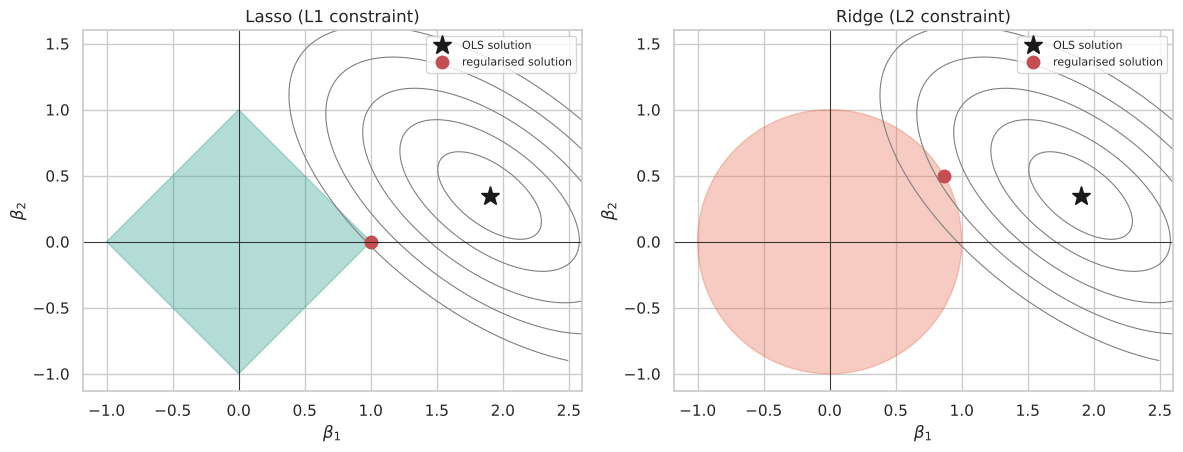

Lasso solution: (1.00, 0.00) | Ridge solution: (0.87, 0.50)


In [16]:
b1, b2 = np.meshgrid(np.linspace(-0.4, 2.6, 400), np.linspace(-0.9, 1.6, 400))
ols_pt = np.array([1.9, 0.35]); A = np.array([[1.0, 0.7], [0.7, 1.4]])
dx, dy = b1 - ols_pt[0], b2 - ols_pt[1]
rss = A[0, 0] * dx ** 2 + 2 * A[0, 1] * dx * dy + A[1, 1] * dy ** 2
t = 1.0; theta = np.linspace(0, 2 * np.pi, 400)

def rss_at(pts):
    d_ = pts - ols_pt
    return A[0, 0] * d_[:, 0] ** 2 + 2 * A[0, 1] * d_[:, 0] * d_[:, 1] + A[1, 1] * d_[:, 1] ** 2

diamond = np.vstack([np.column_stack([np.linspace(t, 0, 200), np.linspace(0, t, 200)]),
                     np.column_stack([np.linspace(0, -t, 200), np.linspace(t, 0, 200)]),
                     np.column_stack([np.linspace(-t, 0, 200), np.linspace(0, -t, 200)]),
                     np.column_stack([np.linspace(0, t, 200), np.linspace(-t, 0, 200)])])
circle = np.column_stack([t * np.cos(theta), t * np.sin(theta)])
pt_l1 = diamond[np.argmin(rss_at(diamond))]; pt_l2 = circle[np.argmin(rss_at(circle))]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, kind, pt in zip(axes, ["Lasso (L1 constraint)", "Ridge (L2 constraint)"], [pt_l1, pt_l2]):
    ax.contour(b1, b2, rss, levels=[0.1, 0.3, 0.6, 1.0, 1.5], colors="gray", linewidths=0.8)
    if kind.startswith("Lasso"): ax.fill([t, 0, -t, 0, t], [0, t, 0, -t, 0], color="#2a9d8f", alpha=0.35)
    else: ax.fill(circle[:, 0], circle[:, 1], color="#e76f51", alpha=0.35)
    ax.plot(*ols_pt, "k*", ms=14, label="OLS solution"); ax.plot(*pt, "ro", ms=9, label="regularised solution")
    ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
    ax.set_title(kind); ax.set_xlabel(r"$\beta_1$"); ax.set_ylabel(r"$\beta_2$"); ax.set_aspect("equal"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()
print("Lasso solution: (%.2f, %.2f) | Ridge solution: (%.2f, %.2f)" % (*pt_l1, *pt_l2))

The solutions printed above are computed numerically on each constraint boundary. For Lasso the best point lies on the $\beta_1$ axis ($\beta_2=0$): **feature selection**. For Ridge both coefficients stay non-zero. (The exact touching point depends on the ellipse orientation and on $t$.)

### 2.7 Hands-on checklist
1. Choose a dataset and preprocess it.
2. Pipeline: `StandardScaler` → `Ridge` / `Lasso`.
3. Tune `alpha` by cross-validation.
4. Evaluate MSE/RMSE and $R^2$ on the test set.
5. Inspect the coefficients: how many are zero, and are they sensible?

## 3. ElasticNet and Regularization

**ElasticNet** blends Ridge and Lasso: useful when features are correlated *and* many are irrelevant. scikit-learn solves

$$\min_{\boldsymbol\beta}\;\frac{1}{2n}\sum_{i=1}^{n}(y_i-\hat y_i)^2+\alpha\rho\sum_{j}\lvert\beta_j\rvert+\frac{\alpha(1-\rho)}{2}\sum_{j}\beta_j^2$$

- `alpha` ($\alpha$): overall strength; `l1_ratio` ($\rho$): the mix ($\rho=1$ is Lasso, $\rho\to0$ is Ridge-like).

### 3.1 The grouping effect

Two **almost identical** features carry the same information. What does each model do with the weight?

In [17]:
r = np.random.default_rng(1)
x1 = r.normal(size=300); x2 = x1 + r.normal(0, 0.01, 300)
Xg = np.column_stack([x1, x2]); yg = 2 * x1 + 2 * x2 + r.normal(0, 0.5, 300)

models_g = {"OLS": LinearRegression(), "Ridge (alpha=1)": Ridge(alpha=1.0), "Lasso (alpha=0.1)": Lasso(alpha=0.1),
            "ElasticNet (alpha=0.1, l1_ratio=0.5)": ElasticNet(alpha=0.1, l1_ratio=0.5)}
rows = {}
for name, m in models_g.items():
    m.fit(Xg, yg); rows[name] = {"coef x1": m.coef_[0], "coef x2": m.coef_[1], "sum": m.coef_.sum()}
pd.DataFrame(rows).T

,coef x1,coef x2,sum
OLS,3.5827,0.3442,3.9269
Ridge (alpha=1),1.9801,1.9374,3.9175
Lasso (alpha=0.1),3.8094,0.0003,3.8097
"ElasticNet (alpha=0.1, l1_ratio=0.5)",1.8794,1.8766,3.7560


Typical behaviour: **OLS** can split the weight unstably (only the sum is well determined), **Ridge** shares it roughly equally, **Lasso** puts (nearly) all weight on one and zeroes the other, and **ElasticNet** shares between them while still shrinking: the **grouping effect**.

### 3.2 The book's recipe: coefficient paths

Following the book, we fit ElasticNet over $\alpha\in\{10^{-4},\dots,10^{2}\}$ and `l1_ratio` $\in\{0.1,0.3,0.5,0.7,0.9\}$ and plot all coefficients.

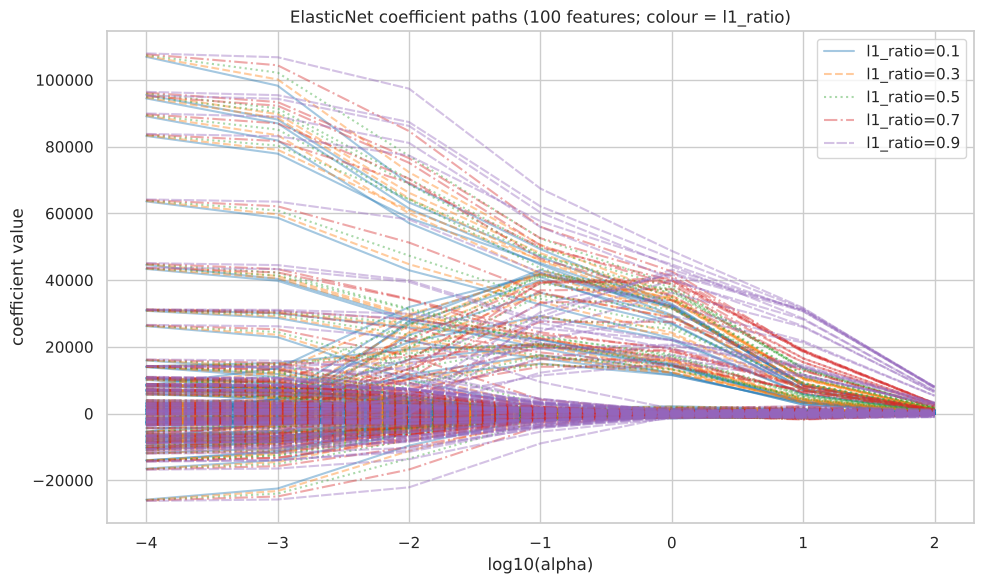

In [18]:
alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]
linestyles = ["solid", "dashed", "dotted", "dashdot", (0, (5, 1))]

plt.figure(figsize=(10, 6))
for idx, (l1_ratio, ls) in enumerate(zip(l1_ratios, linestyles)):
    coefs = np.array([ElasticNet(alpha=al, l1_ratio=l1_ratio, random_state=123, max_iter=10000, tol=1e-4).fit(X_train, y_train).coef_ for al in alphas])
    for j in range(coefs.shape[1]):
        plt.plot(np.log10(alphas), coefs[:, j], linestyle=ls, alpha=0.4, color=plt.cm.tab10(idx), label=f"l1_ratio={l1_ratio}" if j == 0 else None)
plt.xlabel("log10(alpha)"); plt.ylabel("coefficient value")
plt.title("ElasticNet coefficient paths (100 features; colour = l1_ratio)"); plt.legend(); plt.tight_layout(); plt.show()

**How to read it:** x-axis = regularisation strength (log scale), y-axis = coefficient values (each thin line is a feature; 0 means eliminated). Colours/styles distinguish `l1_ratio`: near 0.1 is Ridge-like (smooth shrinkage), near 0.9 Lasso-like (drops features). Because the target is on the scale of $10^5$, the interesting range of $\alpha$ lies above the book's grid, so on the right the lines are not yet at zero. With 100 overlapping lines the plot is hard to read (the book says so too), so we draw cleaner paths with `enet_path`, with signals in red and noise in grey.

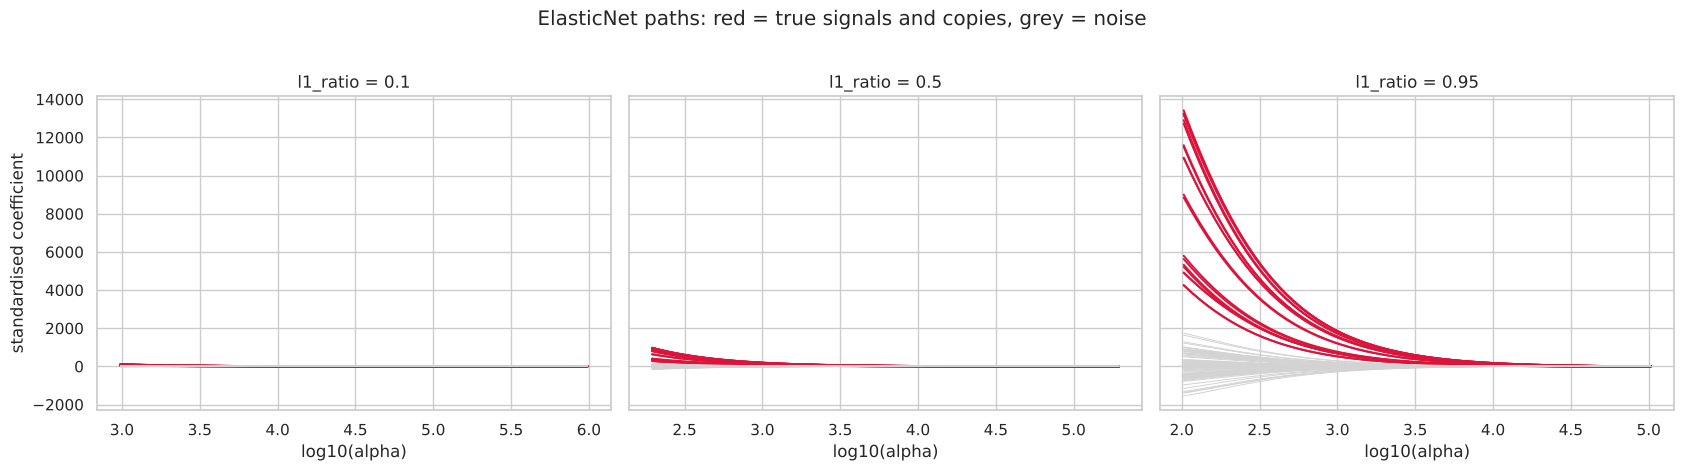

In [19]:
Xs_all = StandardScaler().fit(X_train).transform(X_train); yc_all = y_train - y_train.mean()
informative = set(range(10)) | set(range(50, 60))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for ax, l1r in zip(axes, [0.1, 0.5, 0.95]):
    alphas_path, coefs_path, _ = enet_path(Xs_all, yc_all, l1_ratio=l1r, n_alphas=60)
    for j in range(Xs_all.shape[1]):
        ax.plot(np.log10(alphas_path), coefs_path[j], color="crimson" if j in informative else "lightgray", lw=1.4 if j in informative else 0.7)
    ax.set_title(f"l1_ratio = {l1r}"); ax.set_xlabel("log10(alpha)")
axes[0].set_ylabel("standardised coefficient")
plt.suptitle("ElasticNet paths: red = true signals and copies, grey = noise", y=1.02); plt.tight_layout(); plt.show()

With `l1_ratio=0.1` all coefficients shrink smoothly and signal and noise lines stay entangled longer; with `l1_ratio=0.95` the grey (noise) lines hit exactly zero earlier while the red ones survive: **selection happens**. Lines resistant to shrinkage are the important features; as $\alpha$ grows (moving right) everything shrinks to zero.

### 3.3 Tuning with `ElasticNetCV` and the overall comparison

In [20]:
en_cv = make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0], alphas=60, cv=5, max_iter=50000, random_state=123)).fit(X_train, y_train)
print("ElasticNetCV chose l1_ratio =", en_cv[-1].l1_ratio_, "and alpha = %.2f" % en_cv[-1].alpha_)

elastic_model = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=123, max_iter=10000, tol=1e-4).fit(X_train, y_train)
final = {"Linear Regression": linear_model, "Ridge (book, alpha=1)": ridge_model, "Lasso (book, alpha=10)": lasso_model,
         "ElasticNet (book, alpha=1, l1=0.5)": elastic_model, "RidgeCV (tuned)": ridge_cv, "LassoCV (tuned)": lasso_cv, "ElasticNetCV (tuned)": en_cv}
rows = []
for name, mdl in final.items():
    est = mdl[-1] if hasattr(mdl, "steps") else mdl
    p_ = mdl.predict(X_test)
    rows.append({"model": name, "test MSE": mean_squared_error(y_test, p_), "test R^2": r2_score(y_test, p_), "non-zero coefs": int(np.sum(est.coef_ != 0))})
pd.DataFrame(rows).sort_values("test MSE").reset_index(drop=True)

ElasticNetCV chose l1_ratio = 1.0 and alpha = 804.60


,model,test MSE,test R^2,non-zero coefs
0,LassoCV (tuned),396811114.0755,0.9918,19
1,ElasticNetCV (tuned),396914542.9453,0.9918,18
2,"Lasso (book, alpha=10)",447893932.9551,0.9908,88
3,RidgeCV (tuned),461843392.2219,0.9905,100
4,Linear Regression,462009709.7145,0.9905,100
5,"Ridge (book, alpha=1)",463966207.5089,0.9904,100
6,"ElasticNet (book, alpha=1, l1=0.5)",2732535783.8308,0.9436,100


This reproduces the book's comparison table (sorted by MSE) and adds the lesson that the **tuned** versions do best, with far fewer features for Lasso/ElasticNet.

**Advantages of ElasticNet:** automatic feature selection with graceful handling of correlated features; works for $p>n$ (Lasso can select at most $n$ features); two interpretable hyperparameters tunable jointly.

### 3.4 Hands-on checklist
1. Prepare and standardise the data.
2. Pipeline with `ElasticNet` / `ElasticNetCV`.
3. Vary `alpha` and `l1_ratio`; observe MSE, $R^2$, non-zero coefficients.
4. Plot predicted vs actual and the coefficient paths.

## 4. Regularization Theory and Practice

Regularisation improves **generalisation**. A **loss function** measures how wrong the model is; regularisation **adds a penalty** to it, balancing *goodness of fit* against *simplicity*. Without it a flexible model can memorise noise.

| Concept | Meaning |
|:--------|:--------|
| **Model complexity** | Capacity to fit many functions; high complexity can overfit |
| **$L_1$ (Lasso)** | Sum of absolute coefficients; sparse models |
| **$L_2$ (Ridge)** | Sum of squared coefficients; shrinks, none exactly zero |
| **ElasticNet** | Weighted mix |

### 4.1 The bias-variance trade-off

$$\mathbb E\left[(y-\hat f(x))^2\right]=\underbrace{\left(\mathbb E[\hat f(x)]-f(x)\right)^2}_{\text{bias}^2}+\underbrace{\mathbb E\left[\left(\hat f(x)-\mathbb E[\hat f(x)]\right)^2\right]}_{\text{variance}}+\underbrace{\sigma^2}_{\text{noise}}$$

Regularisation raises bias slightly but cuts variance. We measure this: true function $f(x)=\sin(2\pi x)$, 200 random noisy training sets, a degree-9 polynomial with Ridge for each $\alpha$.

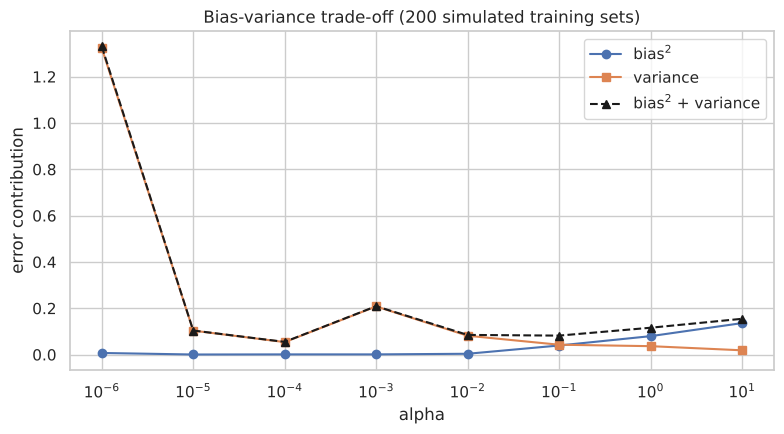

,bias^2,variance,bias^2 + variance
alpha,,,
0.0000,0.0070,1.3237,1.3308
0.0000,0.0004,0.1035,0.1040
0.0001,0.0009,0.0540,0.0549
0.0010,0.0009,0.2080,0.2089
0.0100,0.0036,0.0815,0.0850
0.1000,0.0393,0.0427,0.0820
1.0000,0.0796,0.0364,0.1160
10.0000,0.1360,0.0185,0.1546


In [21]:
rs = np.random.default_rng(123)
f_true = lambda x: np.sin(2 * np.pi * x)
x_eval = np.linspace(0, 1, 100).reshape(-1, 1)
alphas_bv = np.logspace(-6, 1, 8)
n_sims, n_train, noise_sd = 200, 30, 0.3

rows = []
for al in alphas_bv:
    all_preds = np.empty((n_sims, len(x_eval)))
    for s in range(n_sims):
        xs_ = rs.uniform(0, 1, n_train).reshape(-1, 1)
        ys_ = f_true(xs_.ravel()) + rs.normal(0, noise_sd, n_train)
        all_preds[s] = make_pipeline(PolynomialFeatures(9), StandardScaler(), Ridge(alpha=al)).fit(xs_, ys_).predict(x_eval)
    bias2 = np.mean((all_preds.mean(axis=0) - f_true(x_eval.ravel())) ** 2); var = np.mean(all_preds.var(axis=0))
    rows.append({"alpha": al, "bias^2": bias2, "variance": var, "bias^2 + variance": bias2 + var})
bv = pd.DataFrame(rows).set_index("alpha")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(bv.index, bv["bias^2"], "o-", label="bias$^2$"); ax.semilogx(bv.index, bv["variance"], "s-", label="variance")
ax.semilogx(bv.index, bv["bias^2 + variance"], "k^--", label="bias$^2$ + variance")
ax.set_xlabel("alpha"); ax.set_ylabel("error contribution"); ax.set_title("Bias-variance trade-off (200 simulated training sets)"); ax.legend()
plt.tight_layout(); plt.show()
bv.round(4)

With almost no regularisation (left) **variance dominates**; with strong regularisation (right) **bias dominates**; the sum has a minimum at an intermediate $\alpha$, which cross-validation finds in practice.

### 4.2 Which regulariser?
1. Many small effects or correlated features → **Ridge**
2. Sparse truth, interpretability needed → **Lasso**
3. Correlated features *and* many irrelevant ones, or $p>n$ → **ElasticNet**

## 5. Polynomial Regression and Spline Interpolation

A straight line cannot model a curve. Instead of changing the algorithm we **change the features**: powers of $x$ (polynomial regression) or localised basis functions (splines), still fitting a model that is *linear in the coefficients*.

### 5.1 A non-linear dataset (as in the book)

$$y=2x+27\sin\left(\frac{x}{8}\right)+\varepsilon,\qquad x\sim U(-50,50),\;\varepsilon\sim N(0,4^2)$$

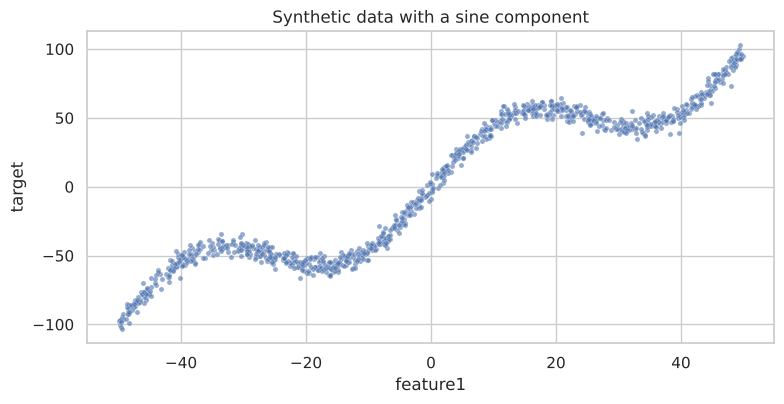

In [22]:
np.random.seed(123)
n_samples = 1000
Xp = np.random.uniform(-50, 50, (n_samples, 1))
yp = 2 * Xp[:, 0] + 27 * np.sin(Xp[:, 0] / 8) + np.random.normal(0, 4, n_samples)
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xp, yp, test_size=0.2, random_state=123)

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.scatterplot(x=Xp[:, 0], y=yp, s=14, alpha=0.6, ax=ax); ax.set_xlabel("feature1"); ax.set_ylabel("target"); ax.set_title("Synthetic data with a sine component")
plt.tight_layout(); plt.show()

### 5.2 Polynomial regression

`PolynomialFeatures(degree=d)` creates $1,x,\dots,x^d$, so the model is $y=\beta_0+\beta_1x+\dots+\beta_dx^d$. Powers of $x\in[-50,50]$ become huge ($50^{15}\approx3\times10^{25}$), making the problem ill-conditioned, so we rescale $x$ to $[-1,1]$ first. We fit degrees 1-5 as in the book plus 9 and 15, and report **test** error too.

In [23]:
def poly_pipeline(degree, reg=None):
    return make_pipeline(MinMaxScaler(feature_range=(-1, 1)), PolynomialFeatures(degree, include_bias=False), reg if reg is not None else LinearRegression())

degrees = [1, 2, 3, 4, 5, 9, 15]
results = []
for d in degrees:
    m = poly_pipeline(d).fit(Xp_tr, yp_tr)
    results.append({"Degree": d,
                    "train RMSE": np.sqrt(mean_squared_error(yp_tr, m.predict(Xp_tr))), "test RMSE": np.sqrt(mean_squared_error(yp_te, m.predict(Xp_te))),
                    "train R2": r2_score(yp_tr, m.predict(Xp_tr)), "test R2": r2_score(yp_te, m.predict(Xp_te))})
results_df = pd.DataFrame(results).set_index("Degree")
results_df

,train RMSE,test RMSE,train R2,test R2
Degree,,,,
1,18.4971,17.8046,0.8804,0.8911
2,18.4968,17.7994,0.8804,0.8912
3,16.6160,16.3853,0.9035,0.9078
4,16.6154,16.3777,0.9035,0.9079
5,6.8192,6.9510,0.9837,0.9834
9,3.8441,3.8632,0.9948,0.9949
15,3.8272,3.9136,0.9949,0.9947


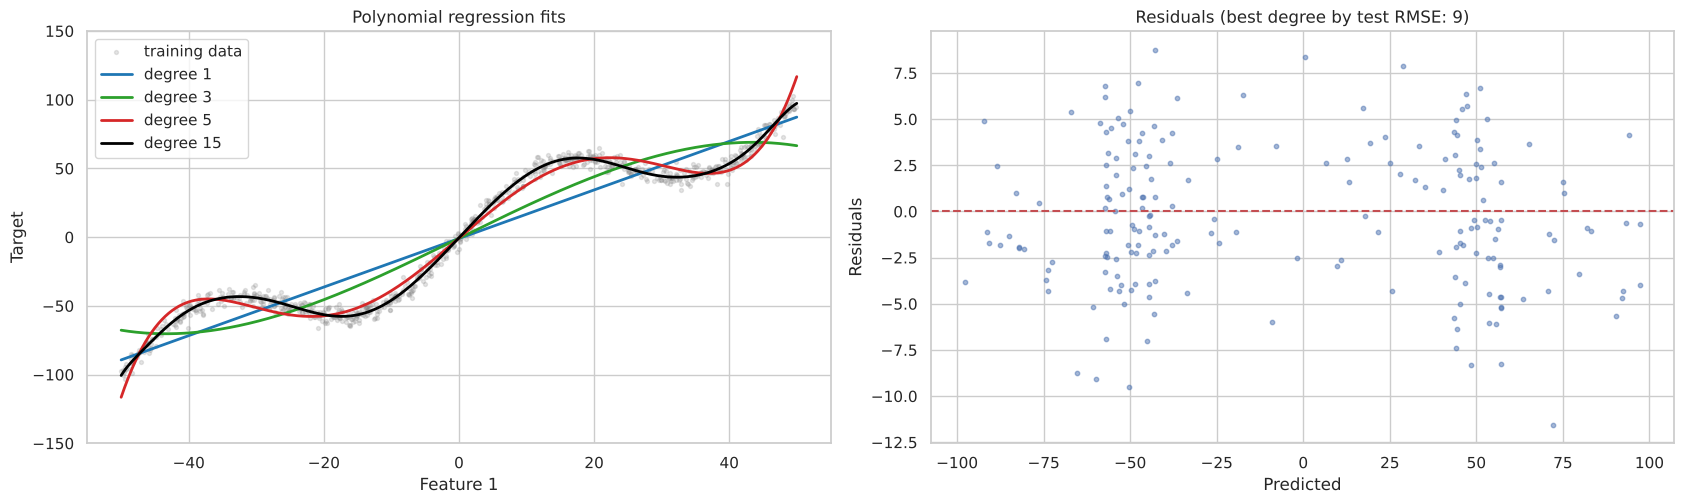

Best degree by test RMSE: 9 | noise level (irreducible RMSE) = 4.0


In [24]:
X_grid = np.linspace(-50, 50, 1000).reshape(-1, 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5.2))
ax1.scatter(Xp_tr, yp_tr, s=8, alpha=0.2, color="gray", label="training data")
for d, color in zip([1, 3, 5, 15], ["tab:blue", "tab:green", "tab:red", "black"]):
    ax1.plot(X_grid, poly_pipeline(d).fit(Xp_tr, yp_tr).predict(X_grid), color=color, lw=2, label=f"degree {d}")
ax1.set_ylim(-150, 150); ax1.set_xlabel("Feature 1"); ax1.set_ylabel("Target"); ax1.set_title("Polynomial regression fits"); ax1.legend(loc="upper left")

best_degree = int(results_df["test RMSE"].idxmin())
pred_best = poly_pipeline(best_degree).fit(Xp_tr, yp_tr).predict(Xp_te)
ax2.scatter(pred_best, yp_te - pred_best, s=10, alpha=0.5); ax2.axhline(0, color="r", ls="--")
ax2.set_xlabel("Predicted"); ax2.set_ylabel("Residuals"); ax2.set_title(f"Residuals (best degree by test RMSE: {best_degree})")
plt.tight_layout(); plt.show()
print("Best degree by test RMSE:", best_degree, "| noise level (irreducible RMSE) = 4.0")

Reading the results: **degree 1** underfits (it cannot follow the sine); errors fall sharply as the degree grows and approach the **noise level of 4**. The book picks the "best" model by the highest $R^2$, but **training $R^2$/RMSE always improves with flexibility**, so choose by *test or cross-validated* error and prefer the simplest model with similar error. Very high degrees can become unstable near the edges (the **Runge phenomenon**), as the table's test error and the degree-15 curve can show.

### 5.3 Taming a polynomial with Ridge

In [25]:
p15_plain = poly_pipeline(15).fit(Xp_tr, yp_tr)
p15_ridge = poly_pipeline(15, RidgeCV(alphas=np.logspace(-6, 2, 40))).fit(Xp_tr, yp_tr)
print("Degree 15 plain OLS : test RMSE = %.3f" % np.sqrt(mean_squared_error(yp_te, p15_plain.predict(Xp_te))))
print("Degree 15 + RidgeCV : test RMSE = %.3f (alpha = %.2e)" % (np.sqrt(mean_squared_error(yp_te, p15_ridge.predict(Xp_te))), p15_ridge[-1].alpha_))

Degree 15 plain OLS : test RMSE = 3.914
Degree 15 + RidgeCV : test RMSE = 3.872 (alpha = 1.70e-05)


### 5.4 Spline interpolation

A **spline** is a piecewise polynomial: the $x$-axis is cut at **knots**, a low-degree (usually cubic) polynomial is fitted in each piece, and the pieces join smoothly. Splines are **local**, which avoids the global edge wiggles of high-degree polynomials. `SplineTransformer` builds a B-spline basis; a linear model on it gives spline regression. Compare 3, 5, 7 knots (as in the book) plus 15 and 30:

In [26]:
rows = []
for k in [3, 5, 7, 15, 30]:
    m = make_pipeline(SplineTransformer(n_knots=k, degree=3), LinearRegression()).fit(Xp_tr, yp_tr)
    rows.append({"Number of Knots": k, "MSE (train)": mean_squared_error(yp_tr, m.predict(Xp_tr)),
                 "MSE (test)": mean_squared_error(yp_te, m.predict(Xp_te)), "R-squared (test)": r2_score(yp_te, m.predict(Xp_te))})
pd.DataFrame(rows).set_index("Number of Knots")

,MSE (train),MSE (test),R-squared (test)
Number of Knots,,,
3,276.0434,268.1404,0.9079
5,55.0467,57.1736,0.9804
7,15.3827,16.2539,0.9944
15,14.5815,15.4382,0.9947
30,14.3813,15.5589,0.9947


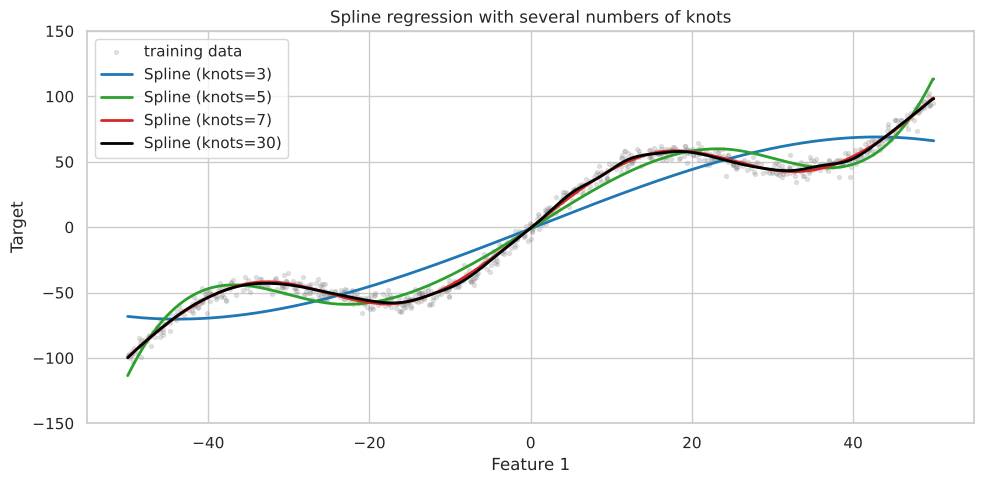

In [27]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(Xp_tr, yp_tr, s=8, alpha=0.2, color="gray", label="training data")
for k, color in zip([3, 5, 7, 30], ["tab:blue", "tab:green", "tab:red", "black"]):
    spl = make_pipeline(SplineTransformer(n_knots=k, degree=3), LinearRegression()).fit(Xp_tr, yp_tr)
    ax.plot(X_grid, spl.predict(X_grid), color=color, lw=2, label=f"Spline (knots={k})")
ax.set_ylim(-150, 150); ax.set_xlabel("Feature 1"); ax.set_ylabel("Target"); ax.set_title("Spline regression with several numbers of knots"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

With 3 knots the spline is too stiff (underfits); with 5-7 knots it follows the curve and approaches the noise floor. More knots always lower the **training** error (the book's observation), but the **test** column shows whether it still helps.

### 5.5 Choosing complexity by cross-validation

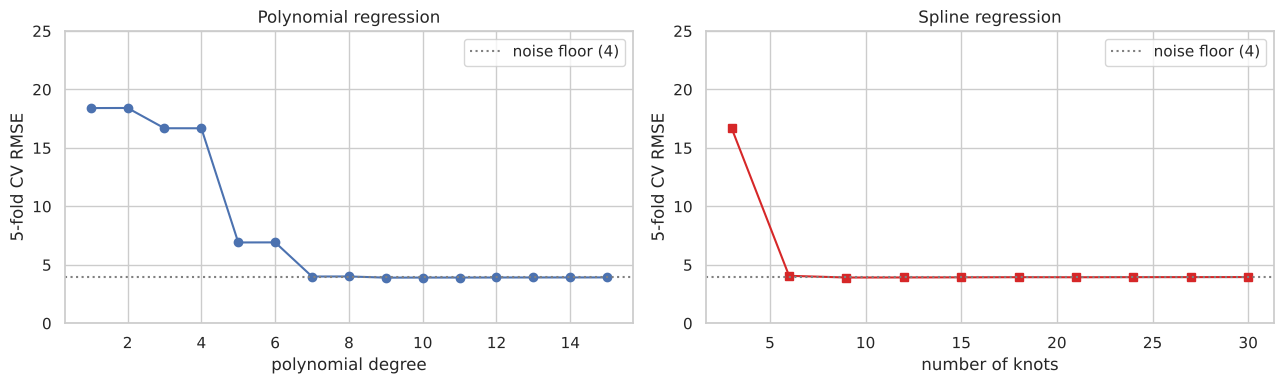

Best degree (CV): 9 (RMSE 3.90) | best knots (CV): 9 (RMSE 3.92)


In [28]:
cv5 = KFold(5, shuffle=True, random_state=123)
deg_range = list(range(1, 16)); knot_range = list(range(3, 31, 3))
cv_poly = [np.sqrt(-cross_val_score(poly_pipeline(d), Xp, yp, cv=cv5, scoring="neg_mean_squared_error").mean()) for d in deg_range]
cv_spl = [np.sqrt(-cross_val_score(make_pipeline(SplineTransformer(n_knots=k, degree=3), LinearRegression()), Xp, yp, cv=cv5, scoring="neg_mean_squared_error").mean()) for k in knot_range]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(deg_range, cv_poly, "o-"); axes[0].set_xlabel("polynomial degree"); axes[0].set_title("Polynomial regression")
axes[1].plot(knot_range, cv_spl, "s-", color="tab:red"); axes[1].set_xlabel("number of knots"); axes[1].set_title("Spline regression")
for ax in axes:
    ax.set_ylabel("5-fold CV RMSE"); ax.set_ylim(0, 25); ax.axhline(4, color="gray", ls=":", label="noise floor (4)"); ax.legend()
plt.tight_layout(); plt.show()
print("Best degree (CV): %d (RMSE %.2f) | best knots (CV): %d (RMSE %.2f)" % (deg_range[int(np.argmin(cv_poly))], min(cv_poly), knot_range[int(np.argmin(cv_spl))], min(cv_spl)))

Both families reach the noise floor once flexible enough and show the typical elbow: a steep drop followed by a plateau.

### 5.6 Hands-on checklist
1. Prepare data; scale before expanding.
2. `PolynomialFeatures` + `LinearRegression`; vary the degree.
3. `SplineTransformer` + `LinearRegression`; vary the knots.
4. Evaluate by test/CV error, not training error.

## 6. Practical Exercises with Regularization Techniques

We use a noisy one-dimensional cubic so results can be plotted, with a flexible **degree-10 polynomial** as the model. Without regularisation it overfits. Each exercise applies one regulariser, with `random_state=123`. Steps: load libraries, generate data, split, fit, predict, compute metrics, visualise (sorting $x$ for a smooth line).

In [29]:
np.random.seed(123)
X_ex = np.random.uniform(-3, 3, size=(120, 1))
y_ex = 0.5 * X_ex[:, 0] ** 3 - X_ex[:, 0] ** 2 + 2 * X_ex[:, 0] + np.random.normal(0, 3, 120)
Xe_tr, Xe_te, ye_tr, ye_te = train_test_split(X_ex, y_ex, test_size=0.3, random_state=123)

def build(reg):
    return make_pipeline(PolynomialFeatures(10, include_bias=False), StandardScaler(), reg)

def run_exercise(name, reg):
    model = build(reg).fit(Xe_tr, ye_tr)
    baseline = build(LinearRegression()).fit(Xe_tr, ye_tr)
    out = {"model": [], "train RMSE": [], "test RMSE": [], "test R^2": []}
    for label, m in [("Degree-10 OLS (no regularisation)", baseline), (name, model)]:
        out["model"].append(label)
        out["train RMSE"].append(np.sqrt(mean_squared_error(ye_tr, m.predict(Xe_tr))))
        out["test RMSE"].append(np.sqrt(mean_squared_error(ye_te, m.predict(Xe_te))))
        out["test R^2"].append(r2_score(ye_te, m.predict(Xe_te)))
    xs = np.sort(X_ex, axis=0)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.scatter(Xe_tr, ye_tr, s=18, color="gray", label="train"); ax.scatter(Xe_te, ye_te, s=22, color="tab:blue", marker="x", label="test")
    ax.plot(xs, baseline.predict(xs), color="tab:orange", lw=1.5, ls="--", label="OLS degree 10")
    ax.plot(xs, model.predict(xs), color="crimson", lw=2.2, label=name); ax.set_ylim(ye_tr.min() - 10, ye_tr.max() + 10)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(loc="upper left"); ax.set_title(f"{name} vs unregularised OLS")
    plt.tight_layout(); plt.show()
    return model, pd.DataFrame(out).set_index("model")

### Exercise 1: Ridge regression

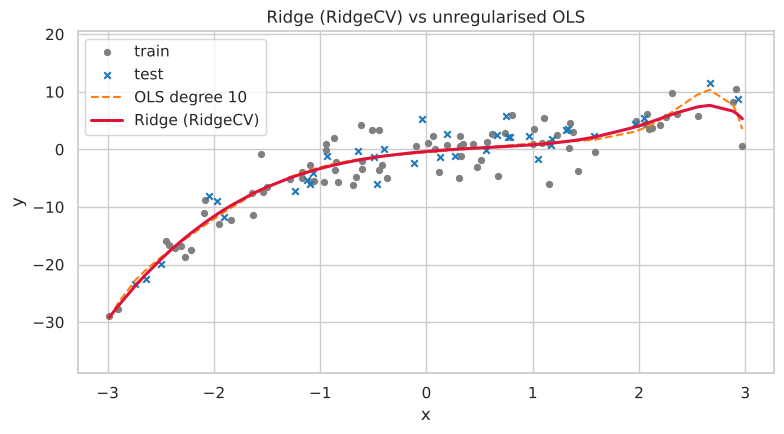

Chosen alpha: 0.5878


,train RMSE,test RMSE,test R^2
model,,,
Degree-10 OLS (no regularisation),2.7457,2.3118,0.9111
Ridge (RidgeCV),2.7771,2.3103,0.9112


In [30]:
ridge_ex, tab1 = run_exercise("Ridge (RidgeCV)", RidgeCV(alphas=np.logspace(-3, 3, 40)))
print("Chosen alpha:", round(ridge_ex[-1].alpha_, 4)); tab1

### Exercise 2: Lasso regression

The true model is a cubic, so ideally Lasso keeps mainly $x,x^2,x^3$.

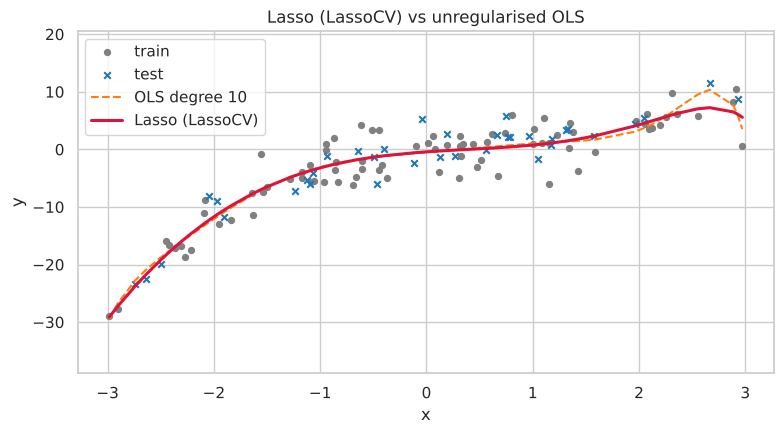

Chosen alpha: 0.0157
Lasso coefficients (standardised features):
x^1     1.9480
x^2    -1.9560
x^3     5.7780
x^4     0.0000
x^5     0.0000
x^6     0.0000
x^7    -0.0000
x^8    -0.0000
x^9    -1.0870
x^10   -0.8590


,train RMSE,test RMSE,test R^2
model,,,
Degree-10 OLS (no regularisation),2.7457,2.3118,0.9111
Lasso (LassoCV),2.7857,2.3516,0.9080


In [31]:
lasso_ex, tab2 = run_exercise("Lasso (LassoCV)", LassoCV(cv=5, alphas=100, max_iter=100000, random_state=123))
coefs = pd.Series(lasso_ex[-1].coef_, index=[f"x^{i}" for i in range(1, 11)])
print("Chosen alpha:", round(lasso_ex[-1].alpha_, 4)); print("Lasso coefficients (standardised features):"); print(coefs.round(3).to_string()); tab2

### Exercise 3: ElasticNet regression

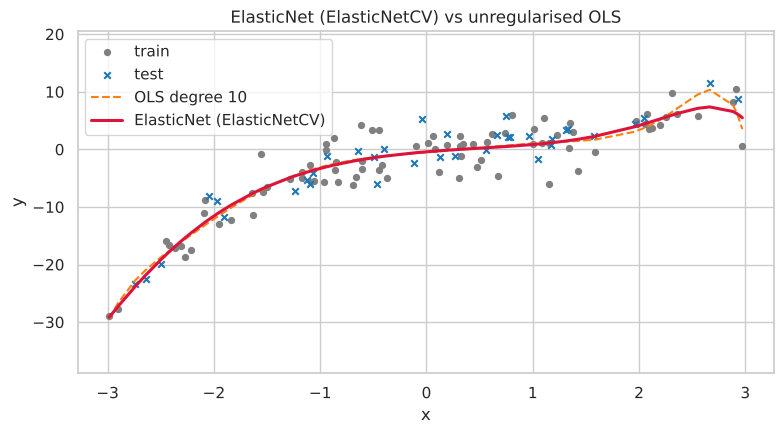

Chosen l1_ratio: 0.5 | alpha: 0.0127 | non-zero coefs: 7 of 10


,train RMSE,test RMSE,test R^2
model,,,
Ridge (RidgeCV),2.7771,2.3103,0.9112
Lasso (LassoCV),2.7857,2.3516,0.9080
ElasticNet (ElasticNetCV),2.7835,2.3187,0.9105
Degree-10 OLS (no regularisation),2.7457,2.3118,0.9111


In [32]:
enet_ex, tab3 = run_exercise("ElasticNet (ElasticNetCV)", ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 1.0], cv=5, alphas=60, max_iter=100000, random_state=123))
print("Chosen l1_ratio:", enet_ex[-1].l1_ratio_, "| alpha:", round(enet_ex[-1].alpha_, 4), "| non-zero coefs:", int(np.sum(enet_ex[-1].coef_ != 0)), "of 10")
pd.concat([tab1.iloc[[1]], tab2.iloc[[1]], tab3.iloc[[1]], tab3.iloc[[0]]])

The final table lines up Ridge, Lasso, ElasticNet and the unregularised baseline. On this simple 1-D problem the degree-10 OLS baseline is already a reasonable fit (noise floor RMSE = 4), so regularisation has little room to help: Ridge's cross-validated alpha is tiny and edges out the baseline by a hair, while Lasso's and ElasticNet's CV-chosen alphas end up fractionally worse on the test split. All four models are within about 0.04 RMSE of each other, well inside run-to-run noise -- the real benefit of Ridge/Lasso/ElasticNet here is the sparser, more interpretable coefficient vector (see Exercise 2), not a large accuracy gain.

### Challenge: which regulariser wins on which kind of data?

Three structures, each tuned by cross-validation, averaged over 5 repetitions: (1) **dense & correlated** (30 features from 5 hidden factors), (2) **sparse** (60 features, 5 informative), (3) **grouped & sparse** (10 groups of 4 correlated features, 3 groups active).

In [33]:
def make_dense_correlated(seed):
    r = np.random.default_rng(seed); Z = r.normal(size=(300, 5)); W = r.normal(size=(5, 30))
    return Z @ W + r.normal(0, 0.5, (300, 30)), Z @ r.normal(size=5) * 3 + r.normal(0, 3, 300)

def make_sparse(seed):
    return make_regression(n_samples=300, n_features=60, n_informative=5, noise=25, random_state=seed)

def make_grouped(seed):
    r = np.random.default_rng(seed); G = r.normal(size=(300, 10))
    X_ = np.hstack([G[:, [g]] + r.normal(0, 0.15, (300, 4)) for g in range(10)])
    return X_, 4 * G[:, 0] + 4 * G[:, 1] - 4 * G[:, 2] + r.normal(0, 3, 300)

regs = {
    "Ridge":      lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 4, 40))),
    "Lasso":      lambda: make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=50000, random_state=0)),
    "ElasticNet": lambda: make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[0.2, 0.5, 0.8, 0.95], cv=5, max_iter=50000, random_state=0)),
}
datasets = {"Dense & correlated": make_dense_correlated, "Sparse": make_sparse, "Grouped & sparse": make_grouped}

table = {}
for ds_name, maker in datasets.items():
    table[ds_name] = {}
    for reg_name, factory in regs.items():
        scores = []
        for seed in range(5):
            X_, y_ = maker(seed)
            Xa, Xb_, ya, yb_ = train_test_split(X_, y_, test_size=0.3, random_state=seed)
            scores.append(np.sqrt(mean_squared_error(yb_, factory().fit(Xa, ya).predict(Xb_))))
        table[ds_name][reg_name] = np.mean(scores)
challenge = pd.DataFrame(table).T
print("Mean test RMSE over 5 repetitions (lower is better):")
challenge.round(3)

Mean test RMSE over 5 repetitions (lower is better):


,Ridge,Lasso,ElasticNet
Dense & correlated,3.2420,3.2660,3.2480
Sparse,28.9950,25.0950,28.0140
Grouped & sparse,3.0840,3.1040,3.0840


In [34]:
winners = challenge.idxmin(axis=1)
print("Winner per data structure:"); print(winners.to_string())
print("\nRelative gap of each method to the best one (%):")
print((challenge.div(challenge.min(axis=1), axis=0).sub(1).mul(100)).round(1))

Winner per data structure:
Dense & correlated    Ridge
Sparse                Lasso
Grouped & sparse      Ridge

Relative gap of each method to the best one (%):
                     Ridge  Lasso  ElasticNet
Dense & correlated  0.0000 0.7000      0.2000
Sparse             15.5000 0.0000     11.6000
Grouped & sparse    0.0000 0.6000      0.0000


Read the winner table and the relative gaps above: when gaps are only a percent or two, the methods are practically tied, because each is tuned by cross-validation. Typically, sparse truths favour Lasso/ElasticNet, dense correlated data favours Ridge, and grouped data favours ElasticNet, but **trust the numbers printed for your run** rather than this expectation. The practical conclusion: tune all three by cross-validation and let the data decide; ElasticNet with a tuned `l1_ratio` contains the other two as special cases, making it a safe default.

## Summary

- **Linear regression** fits $y=\beta_0+\sum\beta_jx_j$ by least squares (the normal equation reproduces `LinearRegression`). Evaluate with MSE/RMSE and $R^2$, check residuals, and beware of **multicollinearity** (high VIF), which makes individual coefficients unreliable while predictions stay fine.
- **Ridge** ($L_2$) shrinks smoothly and cures collinearity (closed form verified); **Lasso** ($L_1$) sets coefficients **exactly to zero** (geometry shown); **ElasticNet** combines both with a **grouping effect**.
- Always **standardise** before regularising, and tune `alpha` (and `l1_ratio`) by **cross-validation**. Test error is U-shaped in $\alpha$.
- Regularisation trades a little **bias** for a large drop in **variance** (simulated).
- **Polynomial regression** and **splines** handle curved relationships by transforming features. Choose complexity by test/CV error; splines are local and more stable than high-degree polynomials; Ridge can tame an over-flexible polynomial.

This completes chapters 1-5 of the *scikit-learn Cookbook*. In **Chapter 6** linear models are extended to classification with **logistic regression**.